# 04 · A testing programme: can a sample-ratio check find broken randomization?

| | |
|---|---|
| **Question** | Would a routine automatic check have caught a randomization bug that is known to have happened? |
| **Data** | Upworthy's headline tests, 2013–2015: 22,743 tests in the confirmatory sample, each showing several versions of a story's headline and image to different visitors. |
| **Answer** | Yes. Without being told when the bug happened, the check flags most tests inside the known problem window and almost none outside it. |
| **Next** | [Notebook 05](05_programme_winners.ipynb) asks how much a winning headline's lift can be trusted. |

**Why this matters.** Companies run thousands of tests a year; nobody can inspect each one by
hand. A check that runs on every test and catches broken ones automatically is worth a lot,
but only if it really catches problems. Part 2 judges Upworthy's whole headline-testing programme, 2013–2015, from the Upworthy Research
Archive (CC BY 4.0). The plan ([`reports/upworthy_analysis_plan.md`](../reports/upworthy_analysis_plan.md))
was written on the exploratory sample and committed before this notebook ran on the
confirmatory sample.

In June 2024 the archive's maintainers reported that tests run between 25 June 2013 and
10 January 2014 may have broken randomization. That gives this notebook something rare: an
answer key. If a routine sample-ratio check works, it should flag tests inside that window far
more often than outside it, without being told where the window is.

**The check:** each test should split its sessions evenly across its packages. Chi-square of
each test's package impressions against an equal split; flag at p < 0.001.
**Confirms if** the flag rate inside the window is at least ten times the rate outside.

**Key terms**

- **Package:** one version of a headline and image within a test.
- **Sample-ratio check:** each package should get about the same number of visitors; a split
  far from even (p < 0.001) means the randomization, or the logging, is broken.
- **p-value under healthy randomization:** if a test is fine, its p-value is equally likely to
  be anywhere from 0 to 1, so only about 1 test in 1,000 is flagged at p < 0.001 by chance.

In [1]:
import os
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "upworthy.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt

from src import records
from src.analysis import programme
from src.data import upworthy

SAMPLE = os.environ.get("UPWORTHY_SAMPLE", "confirmatory")
df = upworthy.load(SAMPLE)
srm = programme.srm_by_test(df)
srm["flagged"] = srm["srm_p"] < 0.001
print(f"{SAMPLE}: {srm.shape[0]:,} tests, {len(df):,} packages, "
      f"{srm['in_window'].mean():.1%} of tests inside the window")

confirmatory: 22,743 tests, 105,551 packages, 21.6% of tests inside the window


## 1. Flag rate inside and outside the window

In [2]:
rates = srm.groupby("in_window")["flagged"].agg(["mean", "sum", "size"]).rename(
    index={False: "outside the window", True: "inside the window"})
ratio = rates.loc["inside the window", "mean"] / rates.loc["outside the window", "mean"]
confirmed = bool(ratio >= 10)
print(f"flag rate inside {rates.loc['inside the window', 'mean']:.1%}, outside "
      f"{rates.loc['outside the window', 'mean']:.2%}; ratio {ratio:.0f}x -> "
      + ("confirms" if confirmed else "does not confirm"))
rates

flag rate inside 70.1%, outside 0.52%; ratio 136x -> confirms


,mean,sum,size
in_window,,,
outside the window,0.005158,92,17836
inside the window,0.700632,3438,4907


**How to read the table.** `mean` is the share of tests flagged, `sum` the number flagged,
`size` the number of tests. Inside the window most tests fail; outside it, only a small fraction
do, so the check separates the two periods by a wide margin.

**The same thing as a picture.** If a test's randomization is healthy, its p-value is spread
out between 0 and 1. Outside the window that is roughly what happens (with a mild lean toward
small values, but very few below 0.001); inside it, the p-values pile up next to zero.

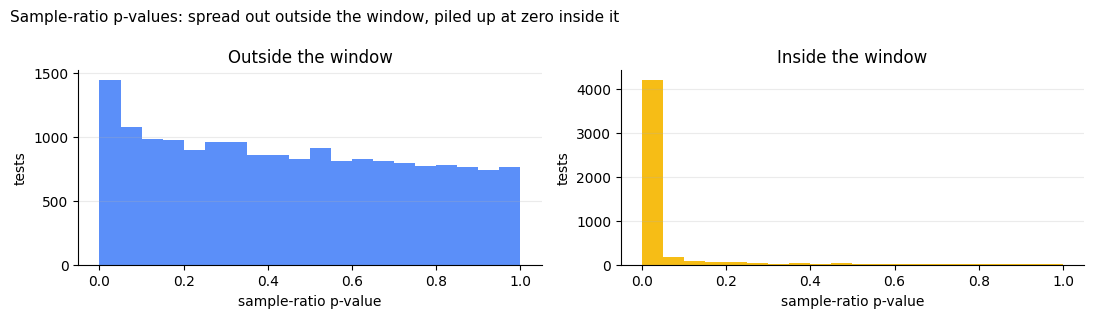

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, inside, title, colour in [(axes[0], False, "Outside the window", "#5B8FF9"),
                                  (axes[1], True, "Inside the window", "#F6BD16")]:
    ax.hist(srm.loc[srm["in_window"] == inside, "srm_p"], bins=20, range=(0, 1), color=colour)
    ax.set(title=title, xlabel="sample-ratio p-value", ylabel="tests")
    ax.grid(alpha=0.25, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Sample-ratio p-values: spread out outside the window, piled up at zero inside it",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

## 2. Month by month

If the check is finding the maintainers' problem, the flag rate should jump at the start of
the window and fall back at its end, not drift.

In [4]:
srm["month"] = srm["test_start"].dt.to_period("M").dt.to_timestamp()
monthly = srm.groupby("month").agg(tests=("flagged", "size"), flag_rate=("flagged", "mean"))
outside_flags = srm[~srm["in_window"] & srm["flagged"]]
print(f"flags outside the window: {len(outside_flags)} tests "
      f"({len(outside_flags) / max(1, srm['flagged'].sum()):.1%} of all flags); "
      f"at p < 0.001 about {0.001 * (~srm['in_window']).sum():.0f} would be expected by chance")
monthly.tail(30).round(3)

flags outside the window: 92 tests (2.6% of all flags); at p < 0.001 about 18 would be expected by chance


,tests,flag_rate
month,,
2013-01-01,9,0.111
2013-02-01,121,0.025
2013-03-01,216,0.046
2013-04-01,399,0.018
2013-05-01,378,0.024
2013-06-01,695,0.217
2013-07-01,811,0.610
2013-08-01,838,0.554
2013-09-01,835,0.653


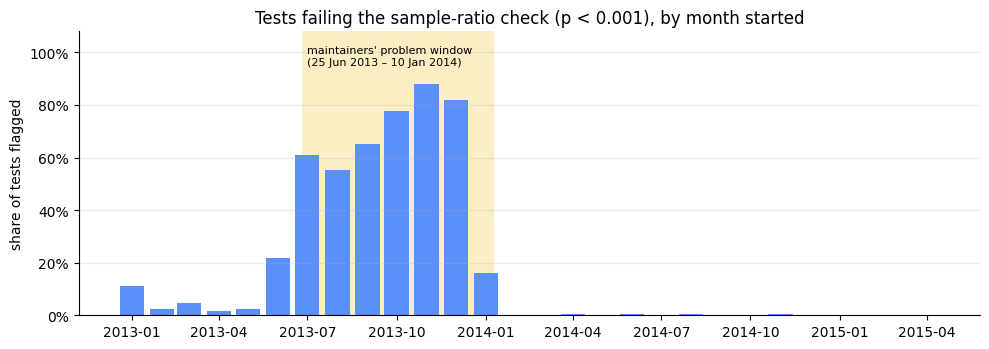

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(upworthy.WINDOW_START, upworthy.WINDOW_END, color="#F6BD16", alpha=0.25, lw=0)
ax.annotate("maintainers' problem window\n(25 Jun 2013 – 10 Jan 2014)", (upworthy.WINDOW_START, 0.97),
            xycoords=("data", "axes fraction"), xytext=(4, -4), textcoords="offset points", va="top", fontsize=8)
ax.bar(monthly.index, monthly["flag_rate"], width=25, color="#5B8FF9")
ax.set(ylim=(0, 1.08), ylabel="share of tests flagged", title="Tests failing the sample-ratio check (p < 0.001), by month started")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(alpha=0.25, axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, f"04_sample_ratio_{SAMPLE}.png", "real")
plt.show()

**How to read the figure.** Each bar is the share of tests started that month that fail the
check; the shaded band is the period the maintainers later said was broken. The flag rate
jumps when the window opens and drops when it closes: the check found the problem by itself.

In [6]:
record = {"sample": SAMPLE, "tests": int(len(srm)), "packages": int(len(df)),
          "share_in_window": float(srm["in_window"].mean()),
          "flag_rate_inside": float(rates.loc["inside the window", "mean"]),
          "flag_rate_outside": float(rates.loc["outside the window", "mean"]),
          "flags_inside": int(rates.loc["inside the window", "sum"]),
          "flags_outside": int(rates.loc["outside the window", "sum"]),
          "ratio": float(ratio), "confirmed": confirmed,
          "monthly": {d.strftime("%Y-%m"): {"tests": int(r.tests), "flag_rate": float(r.flag_rate)}
                      for d, r in monthly.iterrows()}}
print("wrote", records.write(f"04_sample_ratio_{SAMPLE}", record, "real").name)
print(f"Verdict: the check flags {record['flag_rate_inside']:.0%} of tests inside the window and "
      f"{record['flag_rate_outside']:.1%} outside, {ratio:.0f} times as often; "
      + ("the plan's test is passed." if confirmed else "the plan's test is not passed."))

wrote 04_sample_ratio_confirmatory.json
Verdict: the check flags 70% of tests inside the window and 0.5% outside, 136 times as often; the plan's test is passed.


## 3. Power and false discoveries across the programme

Added after the plan's analysis (dated note in the plan). A programme that runs thousands of
tests needs two more numbers: how many tests could detect a difference worth having, and how
many "significant" results it should expect to be false. Both are computed on the tests
notebook 05 uses (outside the problem window, passing the sample-ratio check, packages with at
least 1,000 impressions). Results go to `04b_programme_power_fdr_<sample>.json`.

- **Power:** for each test, the smallest relative difference in click-through between two of
  its packages that it detects with 80% power at a 5% two-sided level, at its median package
  size and its pooled click-through.
- **False discoveries:** each test's chi-square test that all its packages have the same
  click-through, then Benjamini-Hochberg at a 5% false discovery rate, and Storey's estimate of
  the share of tests in which the packages truly do not differ (from p-values above 0.5).

In [7]:
import numpy as np
import pandas as pd
from scipy import stats

from src.analysis.programme import analysis_sample

sample = analysis_sample(df, srm)
per_test = []
for tid, g in sample.groupby(programme.TEST, sort=False):
    n, c = g["impressions"].to_numpy(float), g["clicks"].to_numpy(float)
    p_pool = c.sum() / n.sum()
    n_med = float(np.median(n))
    mde_rel = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * np.sqrt(2 * (1 - p_pool) / (n_med * p_pool))
    table = np.vstack([c, n - c])
    p_value = float(stats.chi2_contingency(table, correction=False)[1]) if (c > 0).all() else np.nan
    per_test.append({"mde_relative": float(mde_rel), "p_homogeneity": p_value, "packages": len(n)})
per_test = pd.DataFrame(per_test).dropna()
pv = np.sort(per_test["p_homogeneity"].to_numpy())
m = len(pv)
passed = pv <= 0.05 * np.arange(1, m + 1) / m
bh_count = int(np.max(np.nonzero(passed)[0]) + 1) if passed.any() else 0
pi0 = float(min(1.0, (pv > 0.5).mean() / 0.5))
power_fdr = {"sample": SAMPLE, "tests": m,
             "mde_relative_quantiles": {q: float(per_test["mde_relative"].quantile(q)) for q in (0.1, 0.25, 0.5, 0.75, 0.9)},
             "share_powered_for_10pct": float((per_test["mde_relative"] <= 0.10).mean()),
             "share_powered_for_20pct": float((per_test["mde_relative"] <= 0.20).mean()),
             "share_p_below_005": float((pv < 0.05).mean()), "bh_discoveries": bh_count,
             "share_bh_discoveries": bh_count / m, "storey_pi0": pi0}
print(f"{m:,} tests: median test detects a {power_fdr['mde_relative_quantiles'][0.5]:.0%} difference between two "
      f"packages; {power_fdr['share_powered_for_10pct']:.0%} can detect 10%. {power_fdr['share_p_below_005']:.0%} have "
      f"p < 0.05; Benjamini-Hochberg keeps {bh_count:,} ({bh_count / m:.0%}) at a 5% FDR; Storey: about "
      f"{pi0:.0%} of tests have packages that truly do not differ.")
print("wrote", records.write(f"04b_programme_power_fdr_{SAMPLE}", power_fdr, "real").name)

17,681 tests: median test detects a 63% difference between two packages; 0% can detect 10%. 45% have p < 0.05; Benjamini-Hochberg keeps 6,353 (36%) at a 5% FDR; Storey: about 35% of tests have packages that truly do not differ.
wrote 04b_programme_power_fdr_confirmatory.json


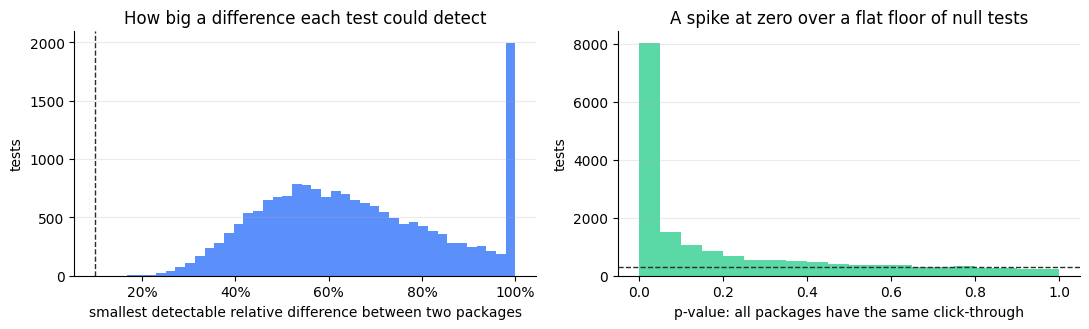

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(per_test["mde_relative"].clip(upper=1), bins=40, color="#5B8FF9")
axes[0].axvline(0.10, color="#2B2B2B", ls="--", lw=1)
axes[0].set(xlabel="smallest detectable relative difference between two packages", ylabel="tests",
            title="How big a difference each test could detect")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].hist(per_test["p_homogeneity"], bins=20, range=(0, 1), color="#5AD8A6")
axes[1].axhline(m / 20 * pi0, color="#2B2B2B", ls="--", lw=1)
axes[1].set(xlabel="p-value: all packages have the same click-through", ylabel="tests",
            title="A spike at zero over a flat floor of null tests")
for ax in axes:
    ax.grid(alpha=0.25, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**How to read the figure.** Left: each test's smallest detectable difference between two of its
packages; the dashed line is 10%. Right: the tests' p-values. Tests whose packages truly do not
differ spread evenly (the dashed line is the level Storey's estimate implies); the spike near
zero is tests with real differences. The height of the floor is what makes "significant at 5%"
an incomplete summary of a programme: some of the spike is the floor. Because the tests are
small, real but undetectable differences also land in the floor, so Storey's estimate is an
upper bound on the share of tests with no real difference; notebook 05's split-sample method
measures the spread between packages without that problem.

## Takeaways

- **A simple automatic check would have caught this bug** long before anyone reported it.
  Running it on every test, and stopping the readout when it fails, is cheap insurance.
- **Each test on its own is small.** Almost none could detect a 10% difference between two
  packages, so a programme like this learns from its tests in aggregate (notebook 05), not from
  any single "significant" result.
- **The tests in the broken window are left out** of the next notebook.

**Next:** [notebook 05](05_programme_winners.ipynb), how much a winning headline's lift can be
trusted.